In [ ]:
import numpy as np

class McCullochPitts:
    def __init__(self, pesos, umbral):
        """
        Inicializa la neurona de McCulloch-Pitts.
        Los pesos y el umbral se mantienen fijos.
        """
        self.pesos = np.array(pesos)
        self.umbral = umbral

    def predecir(self, x):
        """
        Calcula la salida de la neurona para una entrada dada.
        Utiliza una función de activación tipo escalón.
        """
        x_array = np.array(x)
        # Suma ponderada de las entradas
        suma_in = np.dot(x_array, self.pesos)

        # Función de activación escalón adaptada al umbral
        if suma_in >= self.umbral:
            return 1
        else:
            return 0

# ==========================================
# Pruebas para las compuertas lógicas
# ==========================================
if __name__ == "__main__":
    # Entradas posibles para las compuertas de 2 variables
    entradas = [[0, 0], [0, 1], [1, 0], [1, 1]]

    # 1. Compuerta AND (Pesos = [1, 1], Umbral = 2)
    neurona_and = McCullochPitts(pesos=[1, 1], umbral=2)
    print("--- Compuerta AND ---")
    for x in entradas:
        print(f"Entrada: {x} -> Salida: {neurona_and.predecir(x)}")

    # 2. Compuerta OR (Pesos = [1, 1], Umbral = 1)
    neurona_or = McCullochPitts(pesos=[1, 1], umbral=1)
    print("\n--- Compuerta OR ---")
    for x in entradas:
        print(f"Entrada: {x} -> Salida: {neurona_or.predecir(x)}")

    # 3. Compuerta XOR (Demostración de que falla con 1 sola neurona)
    # No importa qué umbral o pesos fijos pongas en una sola neurona,
    # nunca logrará reproducir la tabla de verdad del XOR completa.

--- Compuerta AND ---
Entrada: [0, 0] -> Salida: 0
Entrada: [0, 1] -> Salida: 0
Entrada: [1, 0] -> Salida: 0
Entrada: [1, 1] -> Salida: 1

--- Compuerta OR ---
Entrada: [0, 0] -> Salida: 0
Entrada: [0, 1] -> Salida: 1
Entrada: [1, 0] -> Salida: 1
Entrada: [1, 1] -> Salida: 1


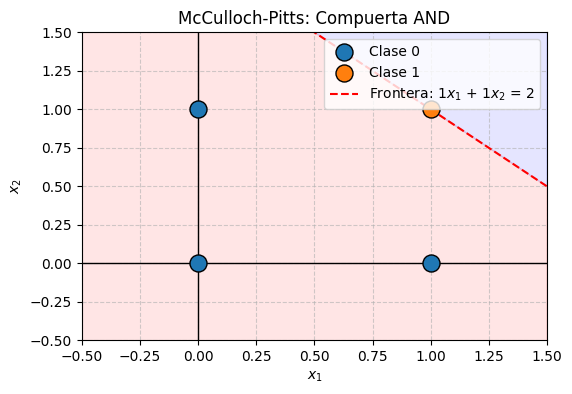

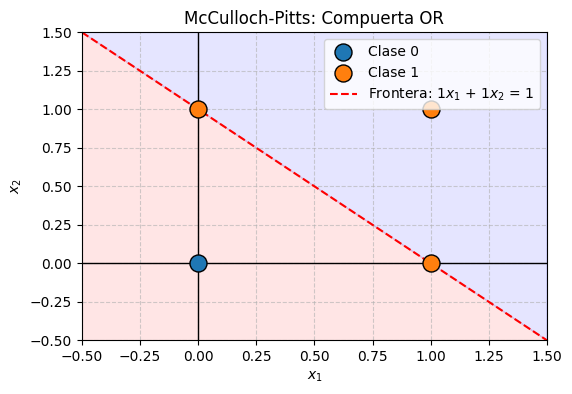

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def graficar_mcculloch_pitts(compuerta, pesos, umbral, entradas, salidas_deseadas):
    plt.figure(figsize=(6, 4))

    entradas = np.array(entradas)
    salidas_deseadas = np.array(salidas_deseadas)

    # Graficar los puntos (Clase 0 y Clase 1)
    for idx, clase in enumerate(np.unique(salidas_deseadas)):
        plt.scatter(entradas[salidas_deseadas == clase, 0],
                    entradas[salidas_deseadas == clase, 1],
                    label=f'Clase {clase}', s=150, edgecolor='k', zorder=3)

    # Definir el rango del plano
    x_min, x_max = -0.5, 1.5
    x1_recta = np.array([x_min, x_max])

    # Ecuación de la recta: w1*x1 + w2*x2 = umbral  =>  x2 = (umbral - w1*x1) / w2
    w1, w2 = pesos
    x2_recta = (umbral - w1 * x1_recta) / w2

    plt.plot(x1_recta, x2_recta, 'r--', label=f'Frontera: {w1}$x_1$ + {w2}$x_2$ = {umbral}')

    # Sombrear las áreas de decisión
    plt.fill_between(x1_recta, x2_recta, x2_recta.min() - 2, color='red', alpha=0.1)
    plt.fill_between(x1_recta, x2_recta, x2_recta.max() + 2, color='blue', alpha=0.1)

    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)

    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)

    plt.title(f'McCulloch-Pitts: Compuerta {compuerta}')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.6, zorder=0)
    plt.show()

# ==========================================
# Generar las gráficas
# ==========================================
if __name__ == "__main__":
    X = [[0, 0], [0, 1], [1, 0], [1, 1]]

    # Gráfica AND: Umbral = 2, Pesos = [1, 1]
    y_and = [0, 0, 0, 1]
    graficar_mcculloch_pitts("AND", pesos=[1, 1], umbral=2, entradas=X, salidas_deseadas=y_and)

    # Gráfica OR: Umbral = 1, Pesos = [1, 1]
    y_or = [0, 1, 1, 1]
    graficar_mcculloch_pitts("OR", pesos=[1, 1], umbral=1, entradas=X, salidas_deseadas=y_or)